In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [16]:
df = pd.read_csv('/content/household_power_consumption.txt.zip',sep=';',na_values=['?'],
    low_memory=False
)

print("The dataset has been loaded successfully!")
print("Number of rows and columns:", df.shape)

display(df.head())


The dataset has been loaded successfully!
Number of rows and columns: (2075259, 9)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.84,18.4,0.0,1.0,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.63,23.0,0.0,1.0,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.29,23.0,0.0,2.0,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.74,23.0,0.0,1.0,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.68,15.8,0.0,1.0,17.0


In [17]:

print("Here is some basic information about the dataset:\n")

df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

print("\nA quick summary of the numerical data:")
display(df.describe().round(2))


Here is some basic information about the dataset:

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2075259 entries, 0 to 2075258
Data columns (total 9 columns):
 #   Column                 Dtype  
---  ------                 -----  
 0   Date                   object 
 1   Time                   object 
 2   Global_active_power    float64
 3   Global_reactive_power  float64
 4   Voltage                float64
 5   Global_intensity       float64
 6   Sub_metering_1         float64
 7   Sub_metering_2         float64
 8   Sub_metering_3         float64
dtypes: float64(7), object(2)
memory usage: 142.5+ MB

Missing values in each column:
Date                         0
Time                         0
Global_active_power      25979
Global_reactive_power    25979
Voltage                  25979
Global_intensity         25979
Sub_metering_1           25979
Sub_metering_2           25979
Sub_metering_3           25979
dtype: int64

A quick summary of the numerical data:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,2049280.00,2049280.00,2049280.00,2049280.00,2049280.00,2049280.00,2049280.00
mean,1.09,0.12,240.84,4.63,1.12,1.30,6.46
std,1.06,0.11,3.24,4.44,6.15,5.82,8.44
min,0.08,0.00,223.20,0.20,0.00,0.00,0.00
25%,0.31,0.05,238.99,1.40,0.00,0.00,0.00
50%,0.60,0.10,241.01,2.60,0.00,0.00,1.00
75%,1.53,0.19,242.89,6.40,0.00,1.00,17.00
max,11.12,1.39,254.15,48.40,88.00,80.00,31.00


In [18]:
df['Date'] = pd.to_datetime(
    df['Date'],
    dayfirst=True,
    errors='coerce'
)

df_12months = df[
    (df['Date'] >= '2009-12-01') &
    (df['Date'] < '2010-12-01')
].copy()

df_12months = df_12months.reset_index(drop=True)

print("Data for our selected period is ready!")
print("Number of rows and columns:", df_12months.shape)
print("Starting date:", df_12months['Date'].min())
print("Ending date:", df_12months['Date'].max())
print("Number of months covered:", df_12months['Date'].dt.to_period('M').nunique())

display(df_12months.head())


Data for our selected period is ready!
Number of rows and columns: (519663, 9)
Starting date: 2009-12-01 00:00:00
Ending date: 2010-11-26 00:00:00
Number of months covered: 12


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,2009-12-01,00:00:00,0.418,0.134,243.94,1.8,0.0,0.0,1.0
1,2009-12-01,00:01:00,0.416,0.134,244.00,1.8,0.0,0.0,1.0
2,2009-12-01,00:02:00,0.414,0.136,244.23,1.8,0.0,0.0,0.0
3,2009-12-01,00:03:00,0.414,0.136,244.52,1.8,0.0,0.0,1.0
4,2009-12-01,00:04:00,0.412,0.136,244.19,1.8,0.0,0.0,1.0


In [19]:
numeric_columns = [
    'Global_active_power',
    'Global_reactive_power',
    'Voltage',
    'Global_intensity',
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

for column in numeric_columns:
    df_12months[column] = pd.to_numeric(
        df_12months[column],
        errors='coerce'
    )

df_12months['DateTime'] = pd.to_datetime(
    df_12months['Date'].dt.strftime('%Y-%m-%d') + ' ' +
    df_12months['Time'],
    errors='coerce'
)

df_12months = df_12months.dropna(subset=['DateTime'])
df_12months = df_12months.drop_duplicates(subset=['DateTime'])
df_12months = df_12months.sort_values('DateTime').reset_index(drop=True)

print("The data has been cleaned and organised!")
print("Rows and columns after cleaning:", df_12months.shape)
print("Missing readings in each measurement column:")
print(df_12months[numeric_columns].isnull().sum())


The data has been cleaned and organised!
Rows and columns after cleaning: (519663, 10)
Missing readings in each measurement column:
Global_active_power      17631
Global_reactive_power    17631
Voltage                  17631
Global_intensity         17631
Sub_metering_1           17631
Sub_metering_2           17631
Sub_metering_3           17631
dtype: int64


In [20]:
df_clean = df_12months.set_index('DateTime').copy()

df_clean[numeric_columns] = df_clean[numeric_columns].interpolate(
    method='time',
    limit=5,
    limit_area='inside'
)

print("Missing readings after filling short gaps:")
print(df_clean[numeric_columns].isnull().sum())

print("\nThe prepared data is ready for analysis.")
display(df_clean.head())


Missing readings after filling short gaps:
Global_active_power      17599
Global_reactive_power    17599
Voltage                  17599
Global_intensity         17599
Sub_metering_1           17599
Sub_metering_2           17599
Sub_metering_3           17599
dtype: int64

The prepared data is ready for analysis.


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
DateTime,,,,,,,,,
2009-12-01 00:00:00,2009-12-01,00:00:00,0.418,0.134,243.94,1.8,0.0,0.0,1.0
2009-12-01 00:01:00,2009-12-01,00:01:00,0.416,0.134,244.00,1.8,0.0,0.0,1.0
2009-12-01 00:02:00,2009-12-01,00:02:00,0.414,0.136,244.23,1.8,0.0,0.0,0.0
2009-12-01 00:03:00,2009-12-01,00:03:00,0.414,0.136,244.52,1.8,0.0,0.0,1.0
2009-12-01 00:04:00,2009-12-01,00:04:00,0.412,0.136,244.19,1.8,0.0,0.0,1.0


In [21]:
print("Electricity Consumption Summary\n")

print("Average power consumption:",
      round(df_clean['Global_active_power'].mean(), 2), "kW")

print("Highest power consumption:",
      round(df_clean['Global_active_power'].max(), 2), "kW")

print("Lowest power consumption:",
      round(df_clean['Global_active_power'].min(), 2), "kW")

print("\nHere is the summary of all measurement columns:")
display(df_clean[numeric_columns].describe().round(2))


Electricity Consumption Summary

Average power consumption: 1.09 kW
Highest power consumption: 9.72 kW
Lowest power consumption: 0.14 kW

Here is the summary of all measurement columns:


,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
count,502064.00,502064.00,502064.00,502064.00,502064.00,502064.00,502064.00
mean,1.09,0.13,241.74,4.58,1.01,1.11,7.36
std,0.95,0.12,3.00,4.00,5.75,5.14,8.74
min,0.14,0.00,225.32,0.60,0.00,0.00,0.00
25%,0.34,0.05,239.91,1.40,0.00,0.00,1.00
50%,0.74,0.10,241.65,3.20,0.00,0.00,1.00
75%,1.53,0.20,243.53,6.40,0.00,1.00,18.00
max,9.72,1.19,254.15,43.00,88.00,80.00,31.00


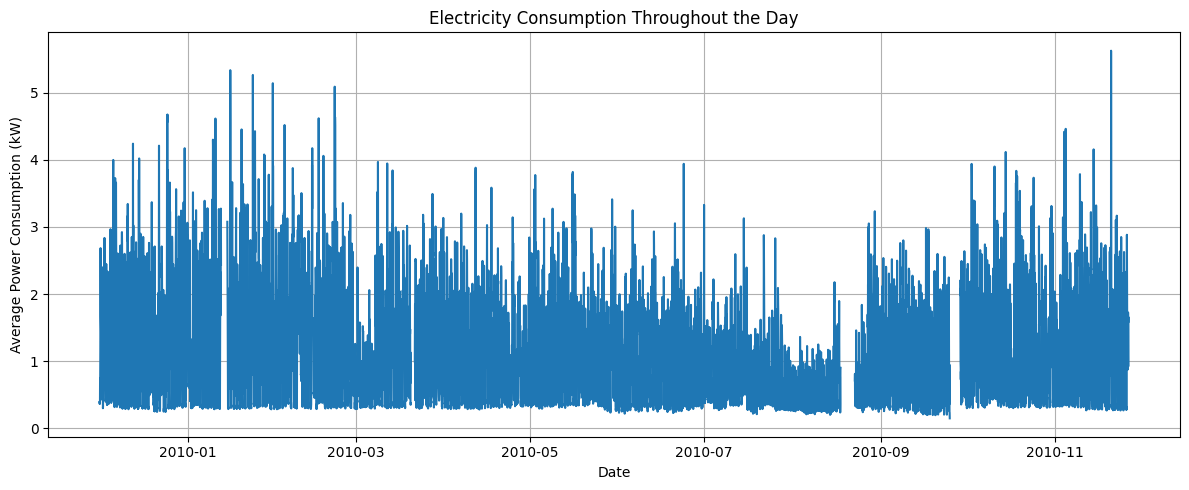

In [22]:
hourly_consumption = df_clean['Global_active_power'].resample('h').mean()

plt.figure(figsize=(12, 5))
plt.plot(hourly_consumption.index, hourly_consumption)
plt.title('Electricity Consumption Throughout the Day')
plt.xlabel('Date')
plt.ylabel('Average Power Consumption (kW)')
plt.grid(True)
plt.tight_layout()
plt.show()


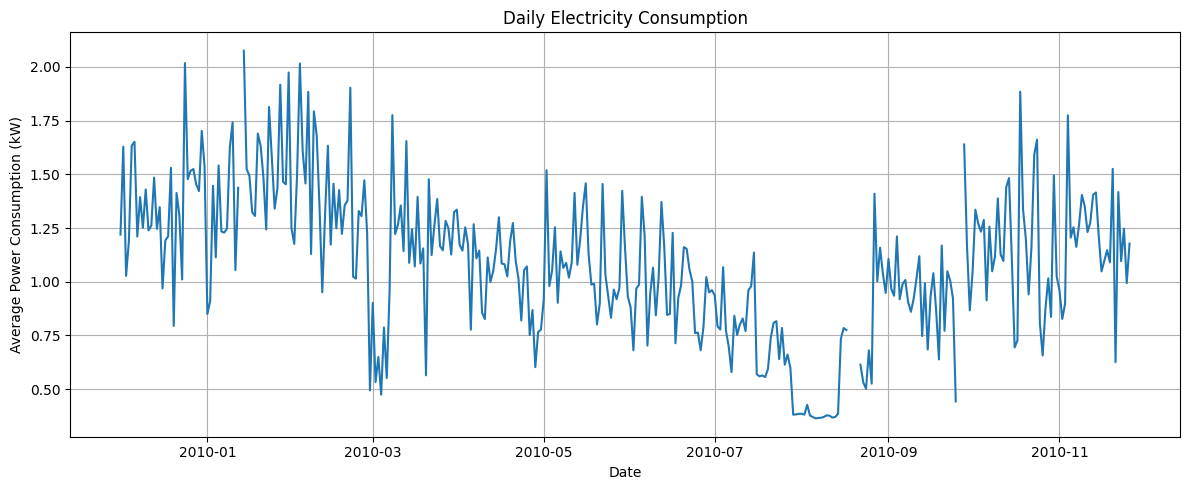

In [23]:
daily_consumption = df_clean['Global_active_power'].resample('D').mean()

plt.figure(figsize=(12, 5))
plt.plot(daily_consumption.index, daily_consumption)
plt.title('Daily Electricity Consumption')
plt.xlabel('Date')
plt.ylabel('Average Power Consumption (kW)')
plt.grid(True)
plt.tight_layout()
plt.show()


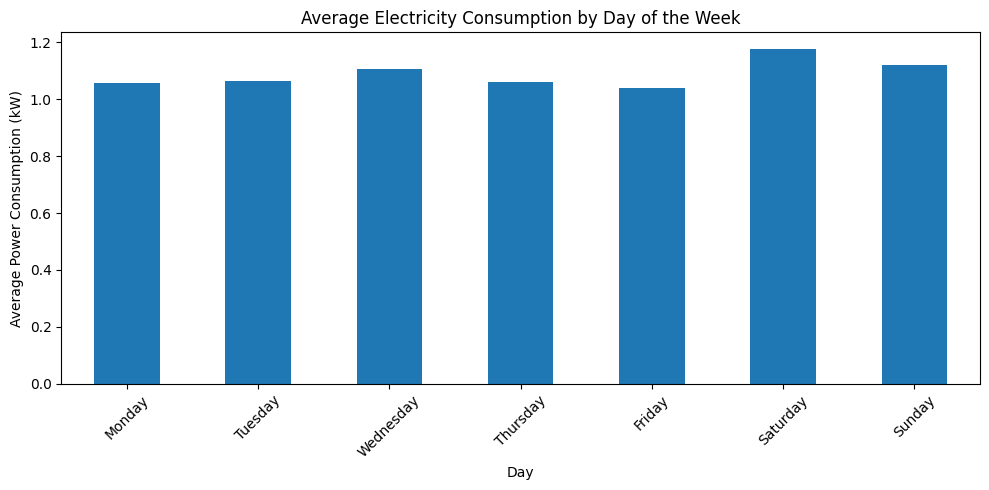

Average consumption for each day:


,Global_active_power
Day,
Monday,1.06
Tuesday,1.06
Wednesday,1.11
Thursday,1.06
Friday,1.04
Saturday,1.18
Sunday,1.12


In [24]:
df_clean['Day'] = df_clean.index.day_name()

days_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

weekly_consumption = df_clean.groupby('Day')[
    'Global_active_power'
].mean().reindex(days_order)

plt.figure(figsize=(10, 5))
weekly_consumption.plot(kind='bar')
plt.title('Average Electricity Consumption by Day of the Week')
plt.xlabel('Day')
plt.ylabel('Average Power Consumption (kW)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

print("Average consumption for each day:")
display(weekly_consumption.round(2))


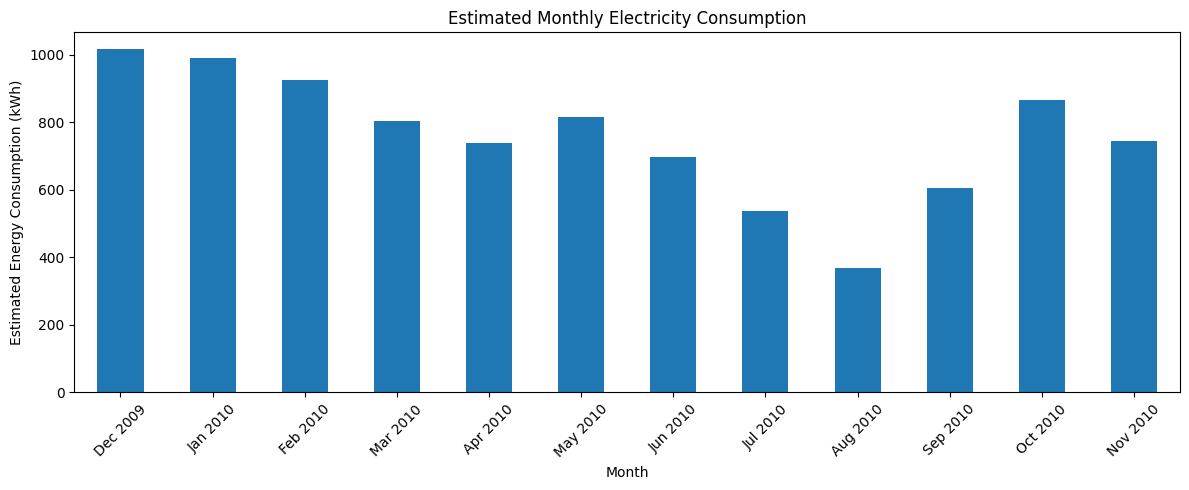

Estimated electricity consumption for each month:


,Global_active_power
DateTime,
2009-12-01,1015.16
2010-01-01,989.90
2010-02-01,924.62
2010-03-01,802.63
2010-04-01,739.64
2010-05-01,814.90
2010-06-01,698.13
2010-07-01,536.51
2010-08-01,368.47


In [25]:
monthly_consumption = (
    df_clean['Global_active_power'].resample('MS').sum(min_count=1) / 60
)

plt.figure(figsize=(12, 5))
monthly_consumption.plot(kind='bar')
plt.title('Estimated Monthly Electricity Consumption')
plt.xlabel('Month')
plt.ylabel('Estimated Energy Consumption (kWh)')
plt.xticks(
    ticks=range(len(monthly_consumption)),
    labels=monthly_consumption.index.strftime('%b %Y'),
    rotation=45
)
plt.tight_layout()
plt.show()

print("Estimated electricity consumption for each month:")
display(monthly_consumption.round(2))


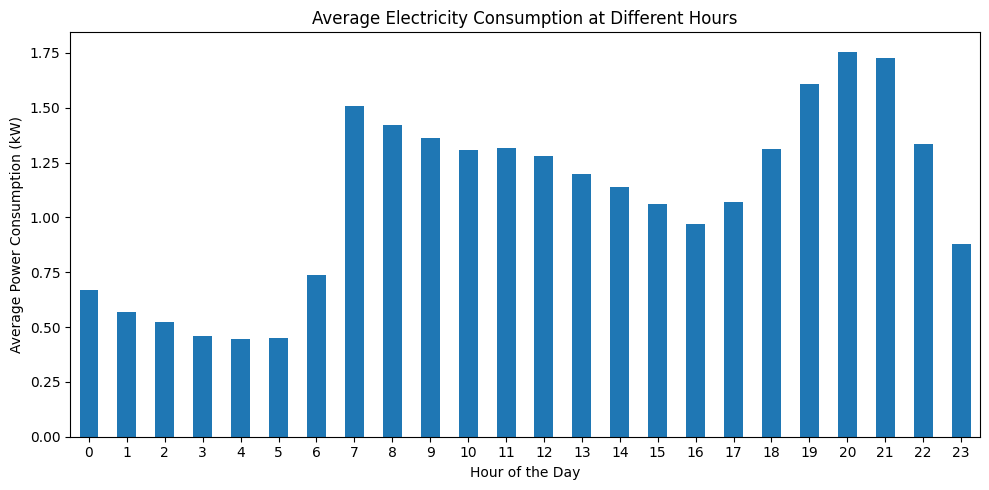

Peak consumption hour: 20:00
Off-peak consumption hour: 04:00


In [26]:
df_clean['Hour'] = df_clean.index.hour

hourly_pattern = df_clean.groupby('Hour')[
    'Global_active_power'
].mean()

peak_hour = hourly_pattern.idxmax()
off_peak_hour = hourly_pattern.idxmin()

plt.figure(figsize=(10, 5))
hourly_pattern.plot(kind='bar')
plt.title('Average Electricity Consumption at Different Hours')
plt.xlabel('Hour of the Day')
plt.ylabel('Average Power Consumption (kW)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("Peak consumption hour:", f"{peak_hour:02d}:00")
print("Off-peak consumption hour:", f"{off_peak_hour:02d}:00")


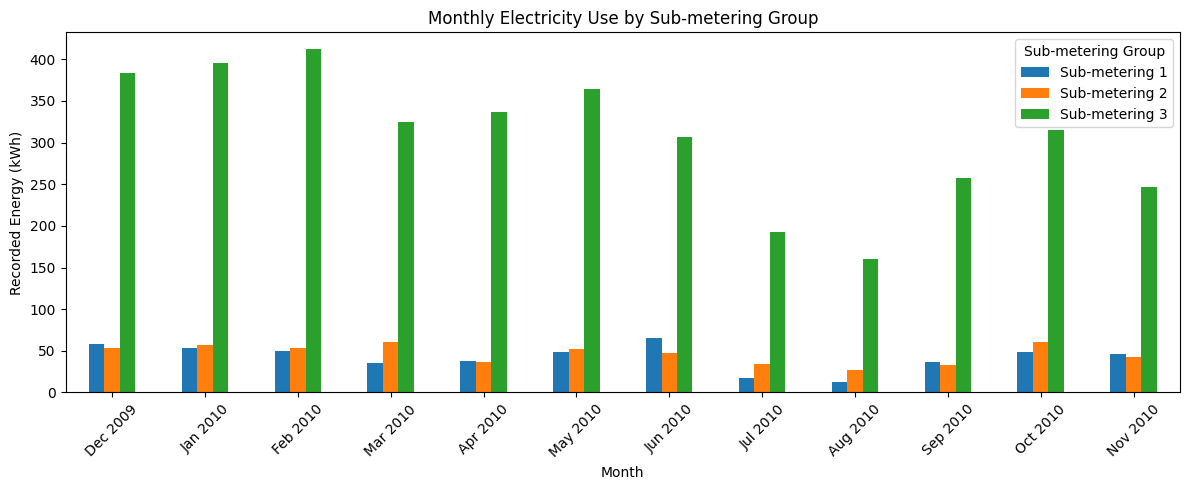

Total recorded energy for each sub-metering group:


,0
Sub-metering 1,509.54
Sub-metering 2,557.45
Sub-metering 3,3697.50


In [27]:
sub_metering_columns = [
    'Sub_metering_1',
    'Sub_metering_2',
    'Sub_metering_3'
]

appliance_consumption = (
    df_clean[sub_metering_columns].resample('MS').sum(min_count=1) / 1000
)

appliance_consumption.columns = [
    'Sub-metering 1',
    'Sub-metering 2',
    'Sub-metering 3'
]

appliance_consumption.plot(
    kind='bar',
    figsize=(12, 5)
)

plt.title('Monthly Electricity Use by Sub-metering Group')
plt.xlabel('Month')
plt.ylabel('Recorded Energy (kWh)')
plt.xticks(
    ticks=range(len(appliance_consumption)),
    labels=appliance_consumption.index.strftime('%b %Y'),
    rotation=45
)
plt.legend(title='Sub-metering Group')
plt.tight_layout()
plt.show()

print("Total recorded energy for each sub-metering group:")
display(appliance_consumption.sum().round(2))


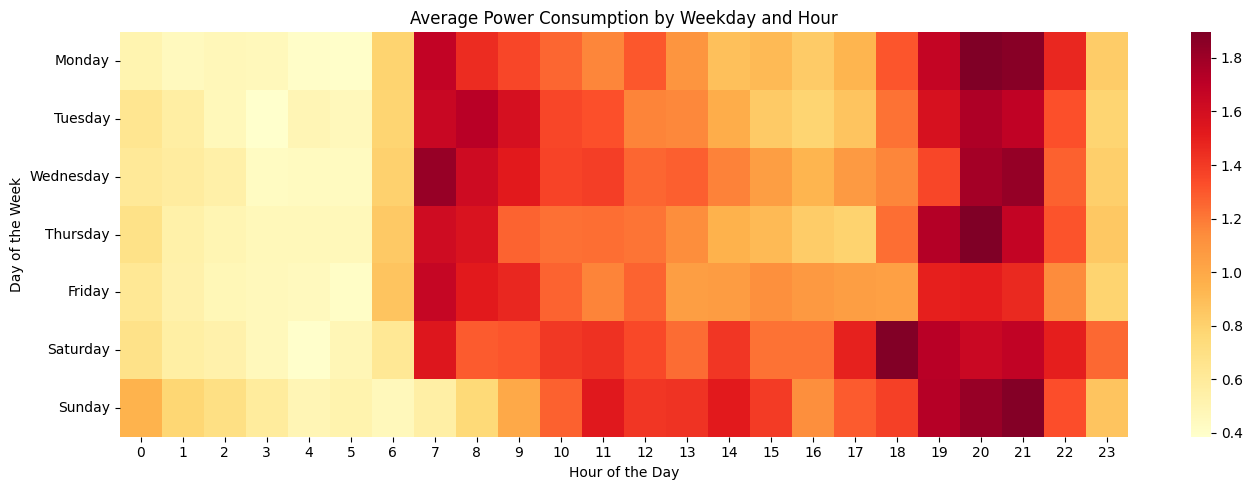

In [28]:
heatmap_data = df_clean.pivot_table(
    index=df_clean.index.dayofweek,
    columns=df_clean.index.hour,
    values='Global_active_power',
    aggfunc='mean'
)

heatmap_data.index = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

plt.figure(figsize=(14, 5))
sns.heatmap(heatmap_data, cmap='YlOrRd')
plt.title('Average Power Consumption by Weekday and Hour')
plt.xlabel('Hour of the Day')
plt.ylabel('Day of the Week')
plt.tight_layout()
plt.show()


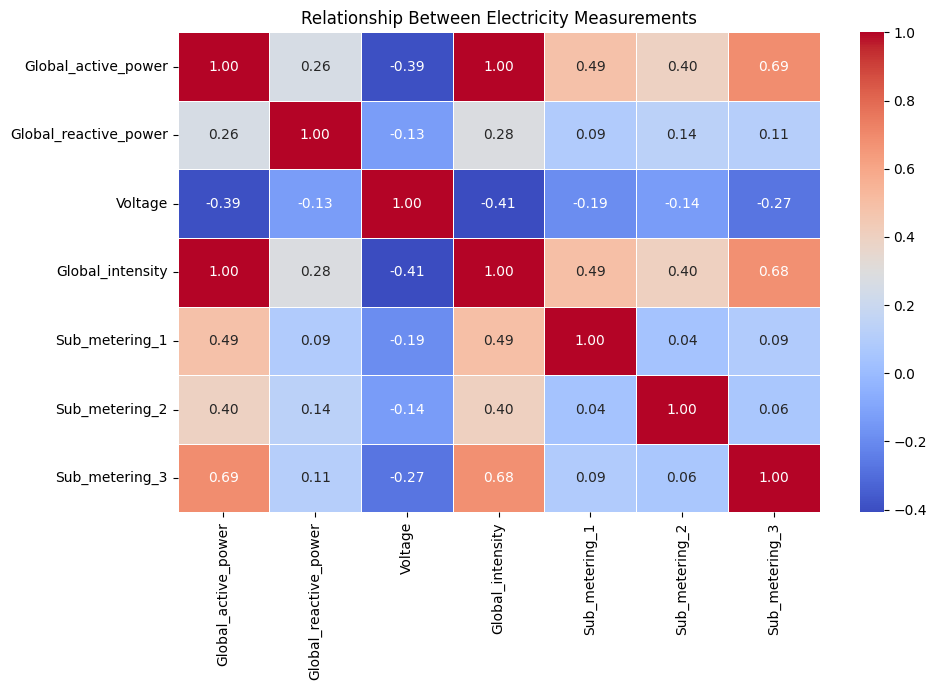

In [29]:
correlation_data = df_clean[numeric_columns].corr()

plt.figure(figsize=(10, 7))
sns.heatmap(
    correlation_data,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Relationship Between Electricity Measurements')
plt.tight_layout()
plt.show()


In [30]:
highest_month = monthly_consumption.idxmax()
lowest_month = monthly_consumption.idxmin()

print("MAIN FINDINGS FROM THE PROJECT\n")

print(
    "Average power consumption:",
    round(df_clean['Global_active_power'].mean(), 2),
    "kW"
)

print(
    "Highest recorded power consumption:",
    round(df_clean['Global_active_power'].max(), 2),
    "kW"
)

print(
    "Month with the highest estimated energy use:",
    highest_month.strftime('%B %Y')
)

print(
    "Month with the lowest estimated energy use:",
    lowest_month.strftime('%B %Y')
)

print("Peak consumption hour:", f"{peak_hour:02d}:00")
print("Off-peak consumption hour:", f"{off_peak_hour:02d}:00")

print("\nEstimated monthly energy consumption:")
display(monthly_consumption.round(2))


MAIN FINDINGS FROM THE PROJECT

Average power consumption: 1.09 kW
Highest recorded power consumption: 9.72 kW
Month with the highest estimated energy use: December 2009
Month with the lowest estimated energy use: August 2010
Peak consumption hour: 20:00
Off-peak consumption hour: 04:00

Estimated monthly energy consumption:


,Global_active_power
DateTime,
2009-12-01,1015.16
2010-01-01,989.90
2010-02-01,924.62
2010-03-01,802.63
2010-04-01,739.64
2010-05-01,814.90
2010-06-01,698.13
2010-07-01,536.51
2010-08-01,368.47



***ENERGY-SAVING RECOMMENDATIONS:***

1. Avoid running high-power appliances unnecessarily.
2. Switch off lights and electrical devices when they are not needed.
3. Check which hours show higher average electricity consumption.
4. Use energy-efficient appliances wherever possible.
5. Monitor electricity consumption regularly to identify unusual changes.
6. Compare monthly energy use to understand changing consumption patterns.


In [31]:
df_clean.to_csv('/content/cleaned_household_power_2010.csv')

monthly_consumption.to_csv(
    '/content/monthly_energy_consumption.csv',
    header=['Estimated_Energy_kWh']
)

results_summary = pd.DataFrame({
    'Metric': [
        'Average Power Consumption (kW)',
        'Highest Recorded Power Consumption (kW)',
        'Peak Consumption Hour',
        'Off-Peak Consumption Hour',
        'Month with Highest Estimated Energy Use',
        'Month with Lowest Estimated Energy Use'
    ],
    'Result': [
        round(df_clean['Global_active_power'].mean(), 2),
        round(df_clean['Global_active_power'].max(), 2),
        f'{peak_hour:02d}:00',
        f'{off_peak_hour:02d}:00',
        highest_month.strftime('%B %Y'),
        lowest_month.strftime('%B %Y')
    ]
})

results_summary.to_csv(
    '/content/energy_analysis_summary.csv',
    index=False
)

print("All project files have been saved successfully!")
display(results_summary)


All project files have been saved successfully!


,Metric,Result
0,Average Power Consumption (kW),1.09
1,Highest Recorded Power Consumption (kW),9.72
2,Peak Consumption Hour,20:00
3,Off-Peak Consumption Hour,04:00
4,Month with Highest Estimated Energy Use,December 2009
5,Month with Lowest Estimated Energy Use,August 2010


In [32]:
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display, HTML

print("Dashboard libraries are ready!")


Dashboard libraries are ready!


In [33]:
hourly_average = df_clean.groupby('Hour')['Global_active_power'].mean()

daily_average = df_clean.groupby(
    df_clean.index.day_name()
)['Global_active_power'].mean()

days_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

daily_average = daily_average.reindex(days_order)

average_power = df_clean['Global_active_power'].mean()
highest_power = df_clean['Global_active_power'].max()
total_energy = monthly_consumption.sum(min_count=1)

display(HTML(f"""
<h1 style="text-align:center;">Energy Consumption and Sustainability Analytics</h1>
<p style="text-align:center;">
Analysis of household electricity consumption from December 2009 to November 2010
</p>
"""))

fig = go.Figure()

fig.add_trace(go.Indicator(
    mode="number",
    value=average_power,
    title={"text": "Average Power (kW)"},
    number={"valueformat": ".2f"},
    domain={"x": [0, 0.33], "y": [0, 1]}
))

fig.add_trace(go.Indicator(
    mode="number",
    value=highest_power,
    title={"text": "Highest Recorded Power (kW)"},
    number={"valueformat": ".2f"},
    domain={"x": [0.34, 0.66], "y": [0, 1]}
))

fig.add_trace(go.Indicator(
    mode="number",
    value=total_energy,
    title={"text": "Estimated Energy (kWh)"},
    number={"valueformat": ",.0f"},
    domain={"x": [0.67, 1], "y": [0, 1]}
))

fig.update_layout(
    title="Electricity Consumption at a Glance",
    height=250
)

fig.show()

monthly_chart = px.bar(
    x=monthly_consumption.index.strftime('%b %Y'),
    y=monthly_consumption.values,
    labels={
        'x': 'Month',
        'y': 'Estimated Energy Consumption (kWh)'
    },
    title='Monthly Electricity Consumption'
)

monthly_chart.show()

hourly_chart = px.line(
    x=hourly_average.index,
    y=hourly_average.values,
    markers=True,
    labels={
        'x': 'Hour of the Day',
        'y': 'Average Power Consumption (kW)'
    },
    title='Average Electricity Consumption by Hour'
)

hourly_chart.update_xaxes(dtick=1)
hourly_chart.show()

weekly_chart = px.bar(
    x=daily_average.index,
    y=daily_average.values,
    labels={
        'x': 'Day of the Week',
        'y': 'Average Power Consumption (kW)'
    },
    title='Average Electricity Consumption by Weekday'
)

weekly_chart.show()

print("MAIN DASHBOARD INSIGHTS\n")
print(f"Average power consumption: {average_power:.2f} kW")
print(f"Highest recorded power consumption: {highest_power:.2f} kW")
print(f"Peak consumption hour: {peak_hour:02d}:00")
print(f"Off-peak consumption hour: {off_peak_hour:02d}:00")
print(
    "Month with highest estimated energy use:",
    monthly_consumption.idxmax().strftime('%B %Y')
)
print(
    "Month with lowest estimated energy use:",
    monthly_consumption.idxmin().strftime('%B %Y')
)

print("\nEnergy-saving suggestions:")
print("1. Switch off electrical devices when they are not needed.")
print("2. Monitor electricity use during peak hours.")
print("3. Compare monthly consumption to identify changes.")
print("4. Choose energy-efficient appliances where possible.")


MAIN DASHBOARD INSIGHTS

Average power consumption: 1.09 kW
Highest recorded power consumption: 9.72 kW
Peak consumption hour: 20:00
Off-peak consumption hour: 04:00
Month with highest estimated energy use: December 2009
Month with lowest estimated energy use: August 2010

Energy-saving suggestions:
1. Switch off electrical devices when they are not needed.
2. Monitor electricity use during peak hours.
3. Compare monthly consumption to identify changes.
4. Choose energy-efficient appliances where possible.
